# Imports and setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats.contingency import association

from churn.config import SEED, TARGET, RAW_PATH, CAT_COLS, NUM_COLS
from churn.data import load_raw, clean

np.random.seed(SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

## Load, clean and read data

In [2]:
df = load_raw(RAW_PATH)

print("================ Shape ================")
print(df.shape)

print("================ Info ================")
print(df.info())

print("================ Describe ================")
print(df.describe())

print("================ Duplicates ================")
print(df.duplicated().sum())

print("================ Missing values ================")
print(df.isna().sum())

print("================ Target imbalance ================")
print(df[TARGET].value_counts(normalize=True))

================ Shape ================
(7043, 33)
================ Info ================
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str   

# Cleaning

In [3]:
df = clean(df)

# Numeric features

## Distributions by churn

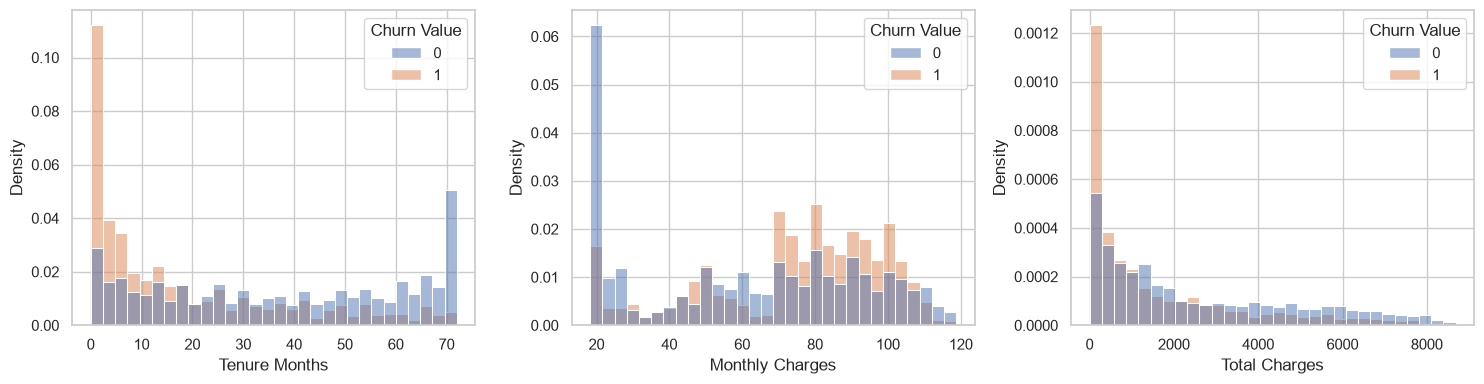

Tenure Months        Monthly Charges        Total Charges        
                     mean median            mean median          mean  median
Churn Value                                                                  
0                    37.6   38.0            61.3   64.4        2549.9  1679.5
1                    18.0   10.0            74.4   79.6        1531.8   703.6

In [4]:

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, NUM_COLS):
    sns.histplot(data=df, x=col, hue=TARGET, bins=30, stat='density', common_norm=False, ax=ax)
plt.tight_layout()
plt.show()

df.groupby(TARGET)[NUM_COLS].agg(["mean", "median"]).round(1)

## Correlations

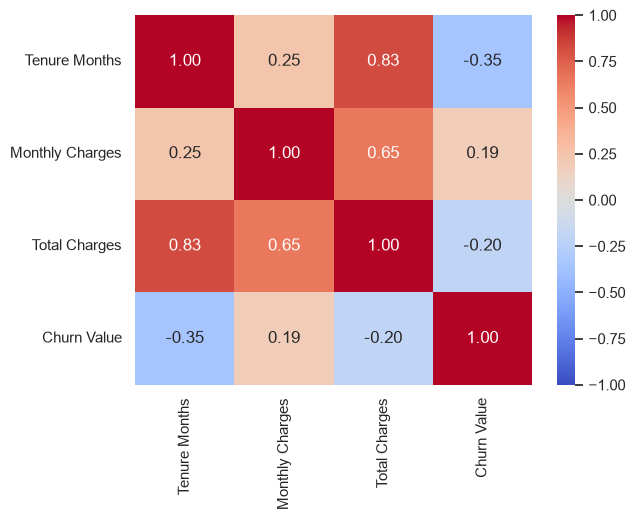

In [5]:
num_cols = ["Tenure Months", "Monthly Charges", "Total Charges"]

sns.heatmap(df[num_cols + [TARGET]].corr(), annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1)
plt.show()

## Outliers (IQR, boxplots)

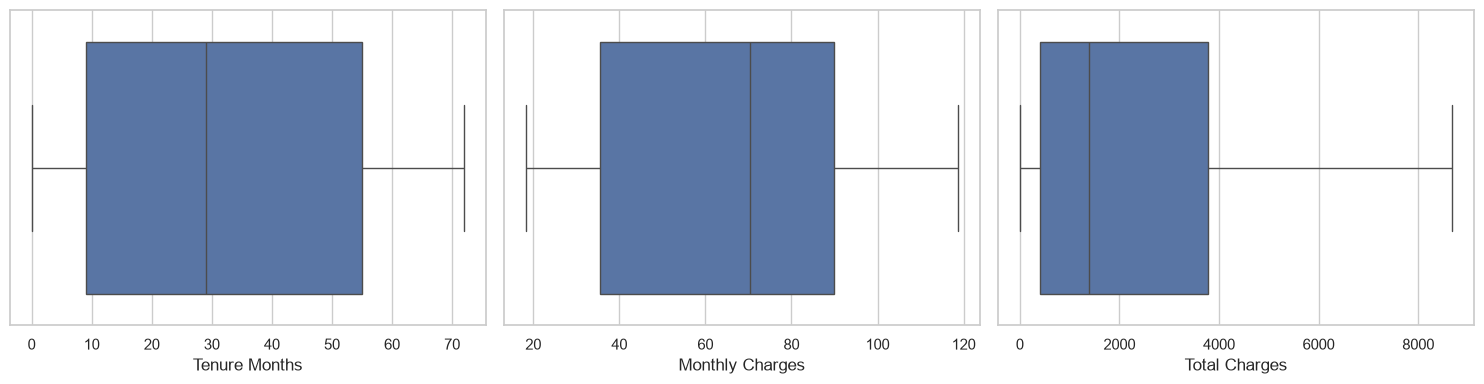

Tenure Months      outliers by IQR rule: 0
Monthly Charges    outliers by IQR rule: 0
Total Charges      outliers by IQR rule: 0


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, NUM_COLS):
    sns.boxplot(data=df, x=col, ax=ax)
plt.tight_layout()
plt.show()

for col in NUM_COLS:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(f"{col:18s} outliers by IQR rule: {n_out}")

# Categorical features

In [7]:
for col in CAT_COLS:
    v = association(pd.crosstab(df[col], df[TARGET]), method="cramer")
    print(f"{col:20s} V={v:.3f}")

Gender               V=0.009
Senior Citizen       V=0.151
Partner              V=0.150
Dependents           V=0.249
Phone Service        V=0.012
Multiple Lines       V=0.040
Internet Service     V=0.322
Online Security      V=0.347
Online Backup        V=0.292
Device Protection    V=0.282
Tech Support         V=0.343
Streaming TV         V=0.231
Streaming Movies     V=0.231
Contract             V=0.410
Paperless Billing    V=0.192
Payment Method       V=0.303


# Conclusions

**Data**
- 7043 customers, 21 columns after cleaning; no duplicates, no missing values after the fix.
- 26.5% churned. A model that always says "stayed" gets ~73% accuracy, so accuracy is not a useful metric.
- `Total Charges` had 11 blank values, all for customers with tenure 0 (new customers). Replaced with 0.

**Columns**
- Dropped: constants (`Count`, `Country`, `State`), duplicate (`Lat Long`), geography (`Zip Code`, `City`, `Latitude`, `Longitude`: 1-5 customers per zip, little power; a hypothesis to re-check), leakage (`Churn Label`, `Churn Score`, `Churn Reason`).
- Kept out of model input: `CLTV` (an estimate from another model, kept for the business cost calculation) and `Total Charges` (correlation 0.9996 with `Tenure x Monthly Charges`; to re-check with tree models).

**Numeric features**
- Churned customers have shorter tenure (median 10 vs 38 months) and higher monthly charges (median 79.6 vs 64.4).
- No outliers by the IQR rule; no clipping needed.

**Categorical features (Cramér's V with churn)**
- Strongest: `Contract` (0.41), `Online Security` (0.35), `Tech Support` (0.34), `Internet Service` (0.32), `Payment Method` (0.30).
- Almost no signal: `Gender` (0.009), `Phone Service` (0.012), `Multiple Lines` (0.040). Kept for now; model feature importance will decide.